In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import yaml

with open("plotting_config.yaml", "r") as fp:
    config = yaml.safe_load(fp)

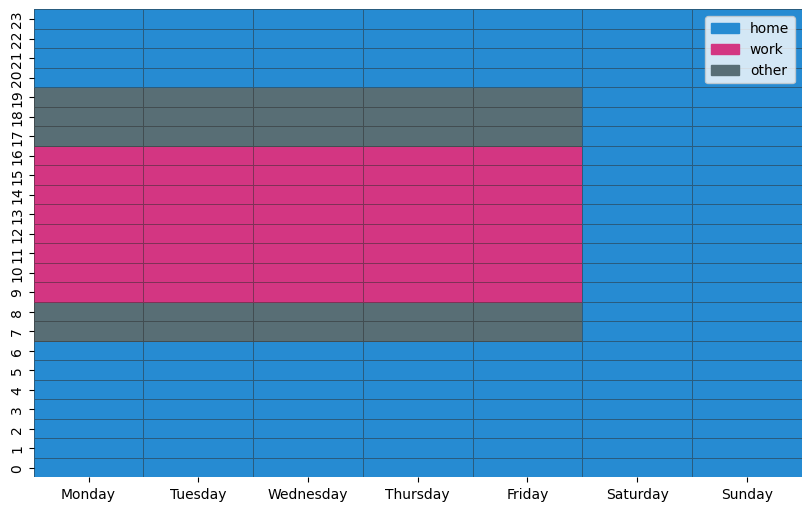

In [2]:
week = np.zeros((24, 7))
for i in range(8):
    week[i] = [1] * 7
for i in range(20, 24):
    week[i] = [1] * 7
for i in range(9, 17):
    week[i] = [2] * 5 + [1, 1]
for i in [7, 8, 17, 18, 19]:
    week[i] = [0] * 5 + [1, 1]

fig, ax = plt.subplots(layout="constrained", figsize=(8, 5))
sns.heatmap(
    ax=ax,
    data=week,
    cbar=False,
    cmap=ListedColormap(["#586e75", "#268bd2", "#d33682"]),
    linecolor="#2d2d2d7f",
    lw=0.5,
)
ax.invert_yaxis()
_ = ax.set_xticklabels(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)
_ = ax.legend(
    handles=[
        Patch(color="#268bd2", label="home"),
        Patch(color="#d33682", label="work"),
        Patch(color="#586e75", label="other"),
    ]
)
for i in ["png", "svg"]:
    fig.savefig(
        f"../docs/figures/home_detection_model.{i}",
        facecolor="none",
        metadata=config["metadata"][i],
    )